# Marked PPP Analysis – Radar Point Clouds

This notebook analyzes predictions of a marked Poisson Point Process (PPP) model
applied to aumovio radar point cloud data.

!!! Note: Here I calculate the GT count repeatedly, but I have now saved it in the meta info as well. TODO: Give it a check i.e. sample["meta"]["ppp_diagnostics"]["gt_count_full"] (as well as the other config entries.) !!!

Use env seg_marked

In [ ]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["image.cmap"] = "hot"

: 

In [17]:
# ROOT_DIR = "."
ROOT_DIR = "/home/uik04723/repos/mmsegmentation_ppp/work_dirs/fast_scnn_mppp_256x512_juwels_260305_test_local_debug/20260313_144600/vis_data/test"

assert os.path.isdir(ROOT_DIR), f"Directory not found: {ROOT_DIR}"

files = sorted(os.listdir(ROOT_DIR))

prefixes = sorted(
    set(
        "_".join(f.split("_")[:5])
        for f in files
        if f.endswith("_meta.json")
    )
)

print(f"Found {len(prefixes)} saved samples.")
print(prefixes[:3])

Found 2 saved samples.
['iter_0000000_test_frame_000000', 'iter_0000000_test_frame_000001']


In [18]:
def load_sample(prefix, root=ROOT_DIR):
    """
    Load one PPP visualization sample.

    Naming / semantics:
      - img: RGB image
      - pred_log_intensity: f(x)
      - pred_lambda_mass: lambda(x) = exp(f(x)) / (H*W)
      - gt_point_support: binary point support {0,1}
    """
    sample = {}
    
    # Core data
    sample["img"] = np.load(os.path.join(root, f"{prefix}_img.npy"))

    sample["pred_log_intensity"] = np.load(
        os.path.join(root, f"{prefix}_pred_log_intensity.npy")
    )

    sample["pred_lambda_mass"] = np.load(
        os.path.join(root, f"{prefix}_pred_lambda_mass.npy")
    )

    sample["gt_point_support"] = np.load(
        os.path.join(root, f"{prefix}_gt_point_support.npy")
    )

    
    # Meta information
    meta_path = os.path.join(root, f"{prefix}_meta.json")
    with open(meta_path, "r") as f:
        sample["meta"] = json.load(f)

    
    # marks
    depth_pred = os.path.join(root, f"{prefix}_pred_depth.npy")
    vel_pred   = os.path.join(root, f"{prefix}_pred_velocity.npy")

    sample["pred_depth"] = np.load(depth_pred) if os.path.exists(depth_pred) else None
    sample["pred_velocity"] = np.load(vel_pred) if os.path.exists(vel_pred) else None

    
    # Derived PPP diagnostics
    lam = sample["pred_lambda_mass"]
    gt  = sample["gt_point_support"]

    H, W = lam.shape

    sample["ppp"] = {
        "H": H,
        "W": W,
        "img_area": H * W,
        "expected_count": float(lam.sum()),
        "gt_count": int(gt.sum()),
        "count_error": float(lam.sum() - gt.sum()),
    }

    return sample


def list_samples(root=ROOT_DIR):
    """
    List all available sample prefixes.

    We key off *_img.npy to stay backward-compatible
    with the visualization hook structure.
    """
    files = sorted(os.listdir(root))
    prefixes = sorted(
        f[:-len("_img.npy")]
        for f in files
        if f.endswith("_img.npy")
    )
    return prefixes

In [19]:
prefixes = list_samples()

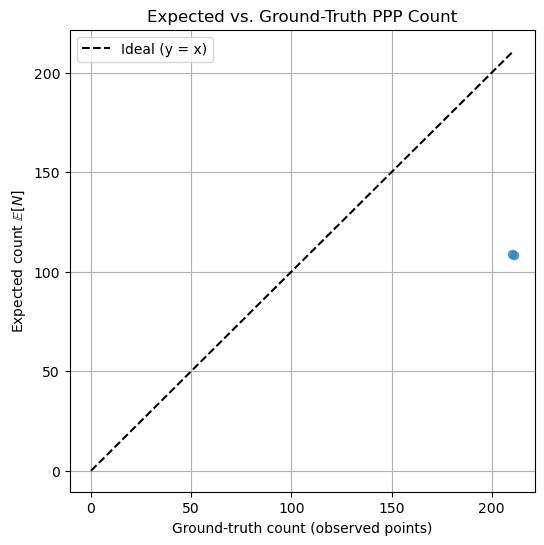

In [20]:
exp_counts = []
gt_counts = []

for prefix in prefixes:
    s = load_sample(prefix)

    # PPP-correct quantities
    lam = s["pred_lambda_mass"]       # lambda(x), already normalized
    gt  = s["gt_point_support"]       # binary {0,1}

    exp_counts.append(lam.sum())       # E[N] = sum lambda(x)
    gt_counts.append(gt.sum())         # observed count

exp_counts = np.array(exp_counts)
gt_counts = np.array(gt_counts)

plt.figure(figsize=(6, 6))
plt.scatter(gt_counts, exp_counts, alpha=0.6)
plt.plot(
    [0, max(gt_counts)],
    [0, max(gt_counts)],
    "k--",
    label="Ideal (y = x)"
)

plt.xlabel("Ground-truth count (observed points)")
plt.ylabel("Expected count $\\mathbb{E}[N]$")
plt.title("Expected vs. Ground-Truth PPP Count")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
from ipywidgets import Dropdown

dropdown = Dropdown(options=prefixes, description="Sample:")
dropdown

Dropdown(description='Sample:', options=('iter_0000000_test_frame_000000_s0', 'iter_0000000_test_frame_000001_…

In [22]:
prefix = dropdown.value
sample = load_sample(prefix)

# idx = 140
# prefix = prefixes[idx]
# sample = load_sample(prefix)

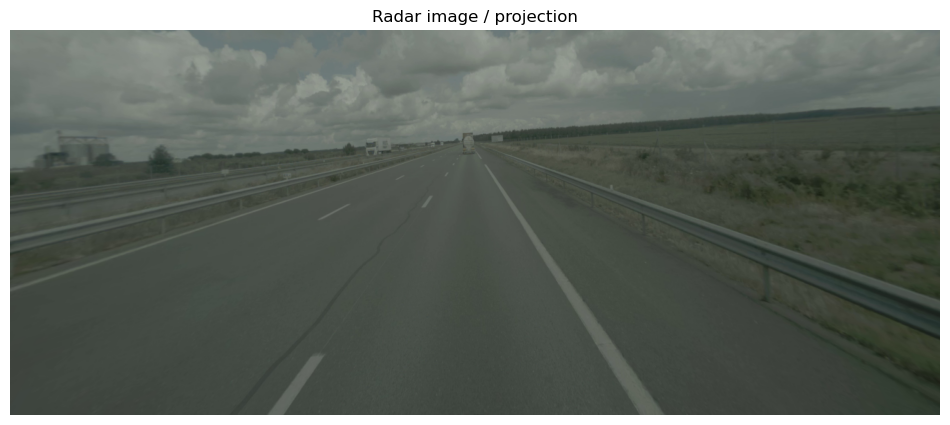

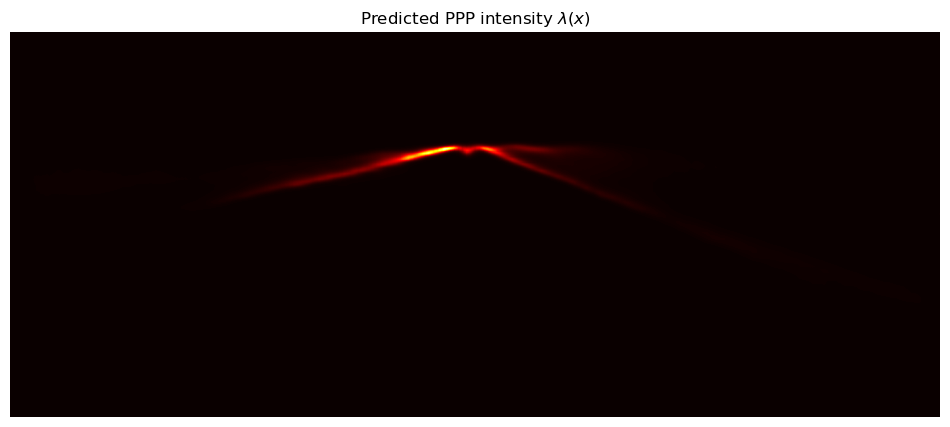

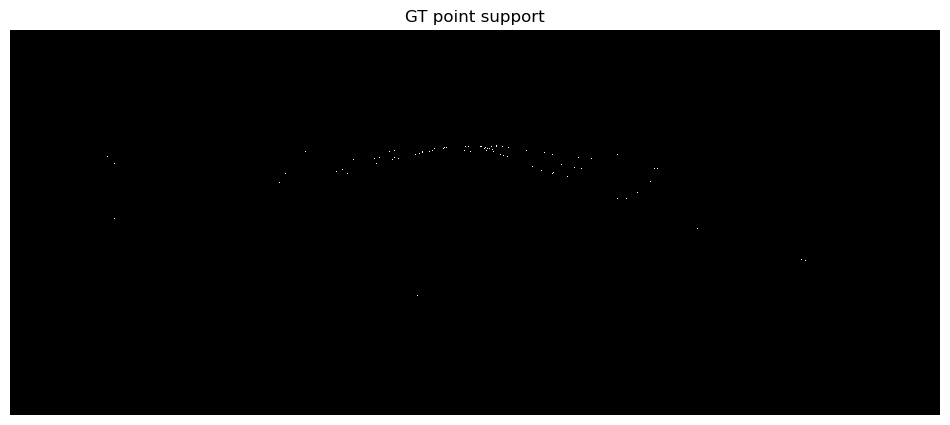

PPP Expected Count
-----------------------------
Expected count: 108.795
GT count: 210
Difference: -101.205


In [23]:
img = sample["img"]
lam = sample["pred_lambda_mass"]
gt  = sample["gt_point_support"]

# --- 1) Radar image ---
plt.figure()
plt.imshow(img, aspect="auto")
plt.title("Radar image / projection")
plt.axis("off")
plt.show()

# --- 2) PPP intensity ---
plt.figure()
plt.imshow(lam, cmap="hot", aspect="auto")
plt.title(r"Predicted PPP intensity $\lambda(x)$")
plt.axis("off")
plt.show()

# --- 3) GT point support ---
plt.figure()
plt.imshow(gt, cmap="gray", interpolation="nearest", aspect="auto")
plt.title("GT point support")
plt.axis("off")
plt.show()

# PPP counts (NO further rescaling!)
expected_count = lam.sum()
gt_count = gt.sum()

print("PPP Expected Count")
print("-----------------------------")
print(f"Expected count: {expected_count:.3f}")
print(f"GT count: {gt_count:.0f}")
print(f"Difference: {expected_count - gt_count:+.3f}")

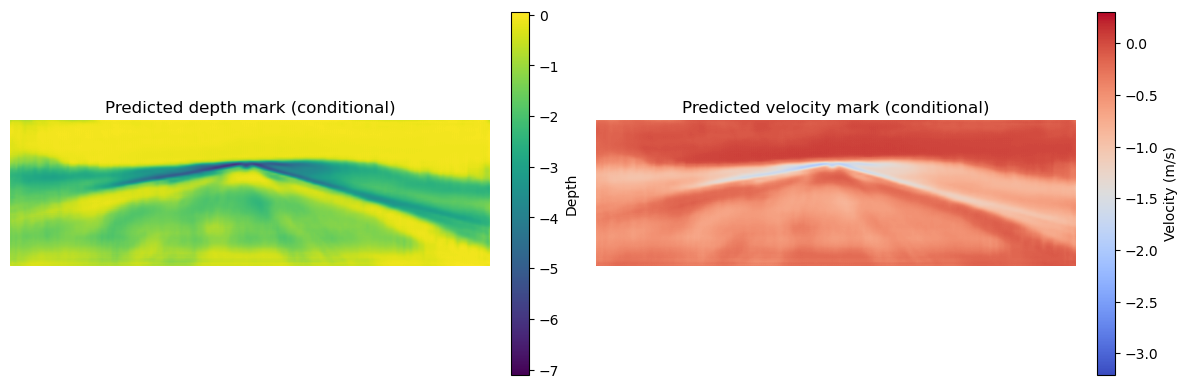

In [24]:
depth = sample["pred_depth"]
vel   = sample["pred_velocity"]

if depth is None and vel is None:
    print("No depth or velocity prediction available.")
else:
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))

    # Depth
    if depth is not None:
        im0 = axs[0].imshow(depth, cmap="viridis")
        axs[0].set_title("Predicted depth mark (conditional)")
        axs[0].axis("off")
        cbar0 = fig.colorbar(im0, ax=axs[0], fraction=0.046, pad=0.04)
        cbar0.set_label("Depth")
    else:
        axs[0].set_title("No depth prediction")
        axs[0].axis("off")

    # Velocity
    if vel is not None:
        im1 = axs[1].imshow(vel, cmap="coolwarm")
        axs[1].set_title("Predicted velocity mark (conditional)")
        axs[1].axis("off")
        cbar1 = fig.colorbar(im1, ax=axs[1], fraction=0.046, pad=0.04)
        cbar1.set_label("Velocity (m/s)")
    else:
        axs[1].set_title("No velocity prediction")
        axs[1].axis("off")

    plt.tight_layout()
    plt.show()


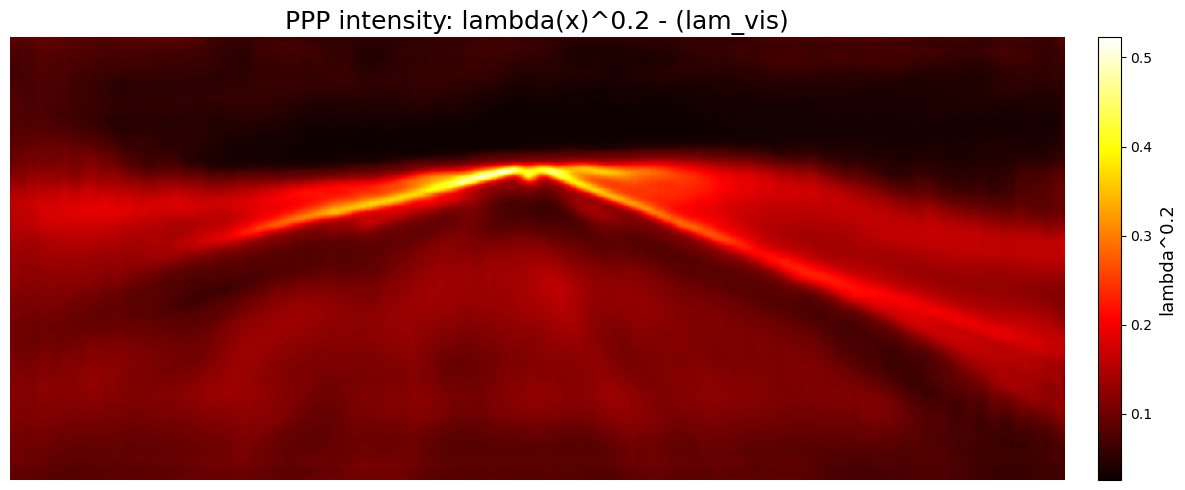

In [25]:
import numpy as np
import matplotlib.pyplot as plt

lam = sample["pred_lambda_mass"]  # raw PPP intensity

gamma = 0.2 # 0.2
lam_vis = lam ** gamma

fig, ax = plt.subplots(1, 1)
im = ax.imshow(lam_vis, cmap="hot", interpolation="nearest", aspect="auto")
ax.set_title(f"PPP intensity: lambda(x)^{gamma} - (lam_vis)", fontsize=18)
ax.axis("off")

cbar = plt.colorbar(im, ax=ax, fraction=0.035, pad=0.03)
cbar.set_label(f"lambda^{gamma}", fontsize=13)

plt.tight_layout()
plt.show()

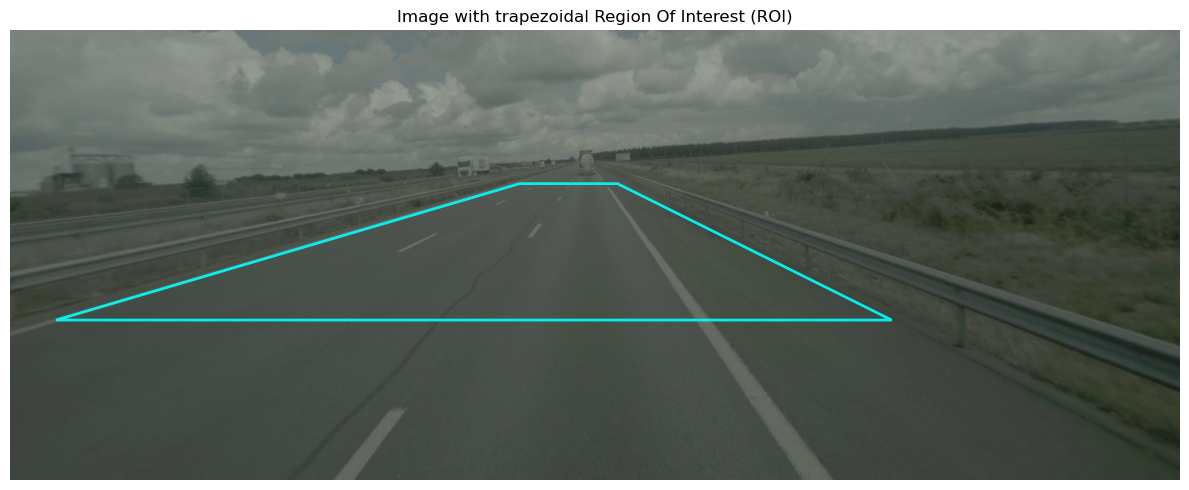

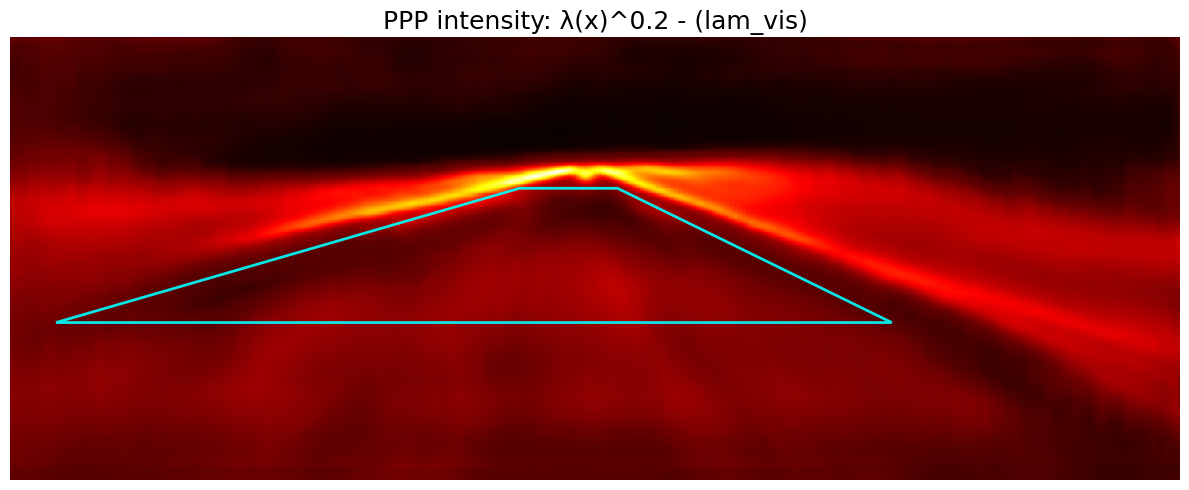

In [26]:
# example trapezoid (x, y) in pixel coordinates
roi_vertices = np.array([
    [780, 185],   # top-left
    [930, 185],   # top-right
    [1350, 350],   # bottom-right
    [70, 350],   # bottom-left
], dtype=float)

from matplotlib.patches import Polygon

def overlay_polygon(ax, vertices, *, color="cyan", lw=2, alpha=0.9):
    poly = Polygon(
        vertices,
        closed=True,
        fill=False,
        edgecolor=color,
        linewidth=lw,
        alpha=alpha,
    )
    ax.add_patch(poly)

fig, ax = plt.subplots(1, 1)

ax.imshow(img, aspect="auto")
overlay_polygon(ax, roi_vertices)

ax.set_title("Image with trapezoidal Region Of Interest (ROI)")
ax.axis("off")

plt.tight_layout()
plt.show()


fig, ax = plt.subplots(1, 1)

im = ax.imshow(
    lam_vis,
    cmap="hot",
    interpolation="nearest",
    aspect="auto"   # visualization choice; ROI still aligns
)

overlay_polygon(ax, roi_vertices, color="cyan", lw=2)

ax.set_title(f"PPP intensity: λ(x)^{gamma} - (lam_vis)", fontsize=18)
ax.axis("off")


plt.tight_layout()
plt.show()


In [27]:
from matplotlib.path import Path
import numpy as np

def polygon_to_mask(vertices, shape):
    """
    vertices : (K,2) array of polygon vertices in (x,y)
    shape    : (H,W) of the image / lambda grid
    """
    H, W = shape
    yy, xx = np.mgrid[:H, :W]
    points = np.stack([xx + 0.5, yy + 0.5], axis=-1)  # pixel centers

    path = Path(vertices)
    mask = path.contains_points(points.reshape(-1, 2))

    return mask.reshape(H, W)


lam = sample["pred_lambda_mass"]   # RAW λ(x), mass per pixel

roi_mask = polygon_to_mask(roi_vertices, lam.shape)

expected_count_roi = lam[roi_mask].sum()
expected_count_total = lam.sum()

print("PPP Expected Count")
print("-----------------------------")
print(f"Total expected count     : {expected_count_total:.3f}")
print(f"ROI expected count       : {expected_count_roi:.3f}")
print(f"Fraction inside ROI      : {expected_count_roi / expected_count_total:.3%}")

Lambda_roi = float(expected_count_roi)  # = lam[roi_mask].sum()

p_empty = np.exp(-Lambda_roi)
p_nonempty = 1.0 - p_empty

print("PPP ROI occupancy")
print("-----------------------------")
print(f"Lambda_ROI (E[N])      : {Lambda_roi:.6f}")
print(f"P(N=0)  empty          : {p_empty:.6f}")
print(f"P(N>=1) at least one   : {p_nonempty:.6f}")


PPP Expected Count
-----------------------------
Total expected count     : 108.795
ROI expected count       : 2.773
Fraction inside ROI      : 2.549%
PPP ROI occupancy
-----------------------------
Lambda_ROI (E[N])      : 2.773395
P(N=0)  empty          : 0.062450
P(N>=1) at least one   : 0.937550


### Point Placement via Thinning of a Homogeneous Poisson Point Process

In [28]:
def sample_ppp_by_thinning(
    lambda_grid: np.ndarray,
    *,
    pixel_area: float,
    rng: np.random.Generator | None = None,
):
    """
    Sample an inhomogeneous PPP using thinning from a homogeneous PPP.

    Parameters
    ----------
    lambda_grid : (H, W) array
        Intensity lambda(x) evaluated on a pixel grid (nonnegative).
        NOTE: lambda_grid is assumed to already represent PPP intensity MASS per pixel.
    pixel_area : float
        Area represented by one pixel (kept for API compatibility, not used).
    rng : np.random.Generator
        Random generator.

    Returns
    -------
    points_xy : (N, 2) array
        Accepted points in image coordinates (x, y).
    N : int
        Number of accepted points.
    lambda_max : float
        Max intensity used for thinning.
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    assert np.all(lam >= 0)

    H, W = lam.shape

    lambda_max = lam.max()
    if lambda_max == 0:
        return np.zeros((0, 2)), 0, 0.0, 0

    # Total intensity of homogeneous PPP
    # lambda_grid already represents intensity mass per pixel,
    # so the domain area is H * W (NOT multiplied by pixel_area).
    area_total = H * W
    Lambda_hom = lambda_max * area_total

    # 1) sample homogeneous PPP
    # N_prop is the number of proposal points in the homogeneous Poisson point process 
    # with intensity lambda_max over the whole image domain.
    N_prop = rng.poisson(Lambda_hom)

    if N_prop == 0:
        return np.zeros((0, 2)), 0, lambda_max, 0

    # uniform proposal locations over image
    xs = rng.random(N_prop) * W
    ys = rng.random(N_prop) * H

    # Converts continuous x-coordinates to integers, Equivalent to floor(xs) for 
    # nonnegative values, Maps point → pixel index
    xi = np.clip(xs.astype(int), 0, W - 1)
    yi = np.clip(ys.astype(int), 0, H - 1)

    # 2) thinning step
    # For each proposed point (xi,yi), we evaluate the predicted intensity at its location 
    # by looking up the corresponding pixel in lambda_grid.
    lam_x = lam[yi, xi]
    accept_prob = lam_x / lambda_max

    # this performs independent Bernoulli trials for all proposal points:
    # Each proposal point is kept if its random number is smaller than its acceptance probability
    keep = rng.random(N_prop) < accept_prob

    # Finally, we collect the coordinates of all accepted points.
    points_xy = np.stack([xs[keep], ys[keep]], axis=1)

    return points_xy, points_xy.shape[0], float(lambda_max), N_prop


def visualize_gt_ppp_heatmap(
    img,
    gt_points_xy,
    ppp_points_xy,
    lambda_grid,
    *,
    point_size=6,
    cmap="viridis",
):
    fig, axes = plt.subplots(
        3, 1,
        figsize=(12, 14),
        sharex=True,
        sharey=True
    )

    # --- Ground Truth ---
    axes[0].imshow(img)
    if len(gt_points_xy) > 0:
        axes[0].scatter(
            gt_points_xy[:, 0],
            gt_points_xy[:, 1],
            s=point_size,
            c="lime",
            alpha=0.9,
        )
    axes[0].set_title(f"Ground Truth (N={len(gt_points_xy)})")
    axes[0].axis("off")

    # --- PPP result ---
    axes[1].imshow(img)
    if len(ppp_points_xy) > 0:
        axes[1].scatter(
            ppp_points_xy[:, 0],
            ppp_points_xy[:, 1],
            s=point_size,
            c="red",
            alpha=0.8,
        )
    axes[1].set_title(f"PPP point cloud (N={len(ppp_points_xy)})")
    axes[1].axis("off")

    # --- Heatmap ---
    im = axes[2].imshow(lambda_grid, cmap=cmap)
    axes[2].set_title("Predicted PPP intensity mass per pixel lambda")
    axes[2].axis("off")
    plt.colorbar(im, ax=axes[2], fraction=0.046)

    plt.tight_layout()
    plt.show()


def extract_gt_points_from_mask(mask):
    # turns mask into x,y coordinates
    ys, xs = np.where(mask > 0)
    return np.stack([xs + 0.5, ys + 0.5], axis=1)



Lambda max: 0.03893863854288053
Accepted points: 106
Expected count: 108.79458645979207
GT count: 210
Acceptance rate: 0.002795506092093465


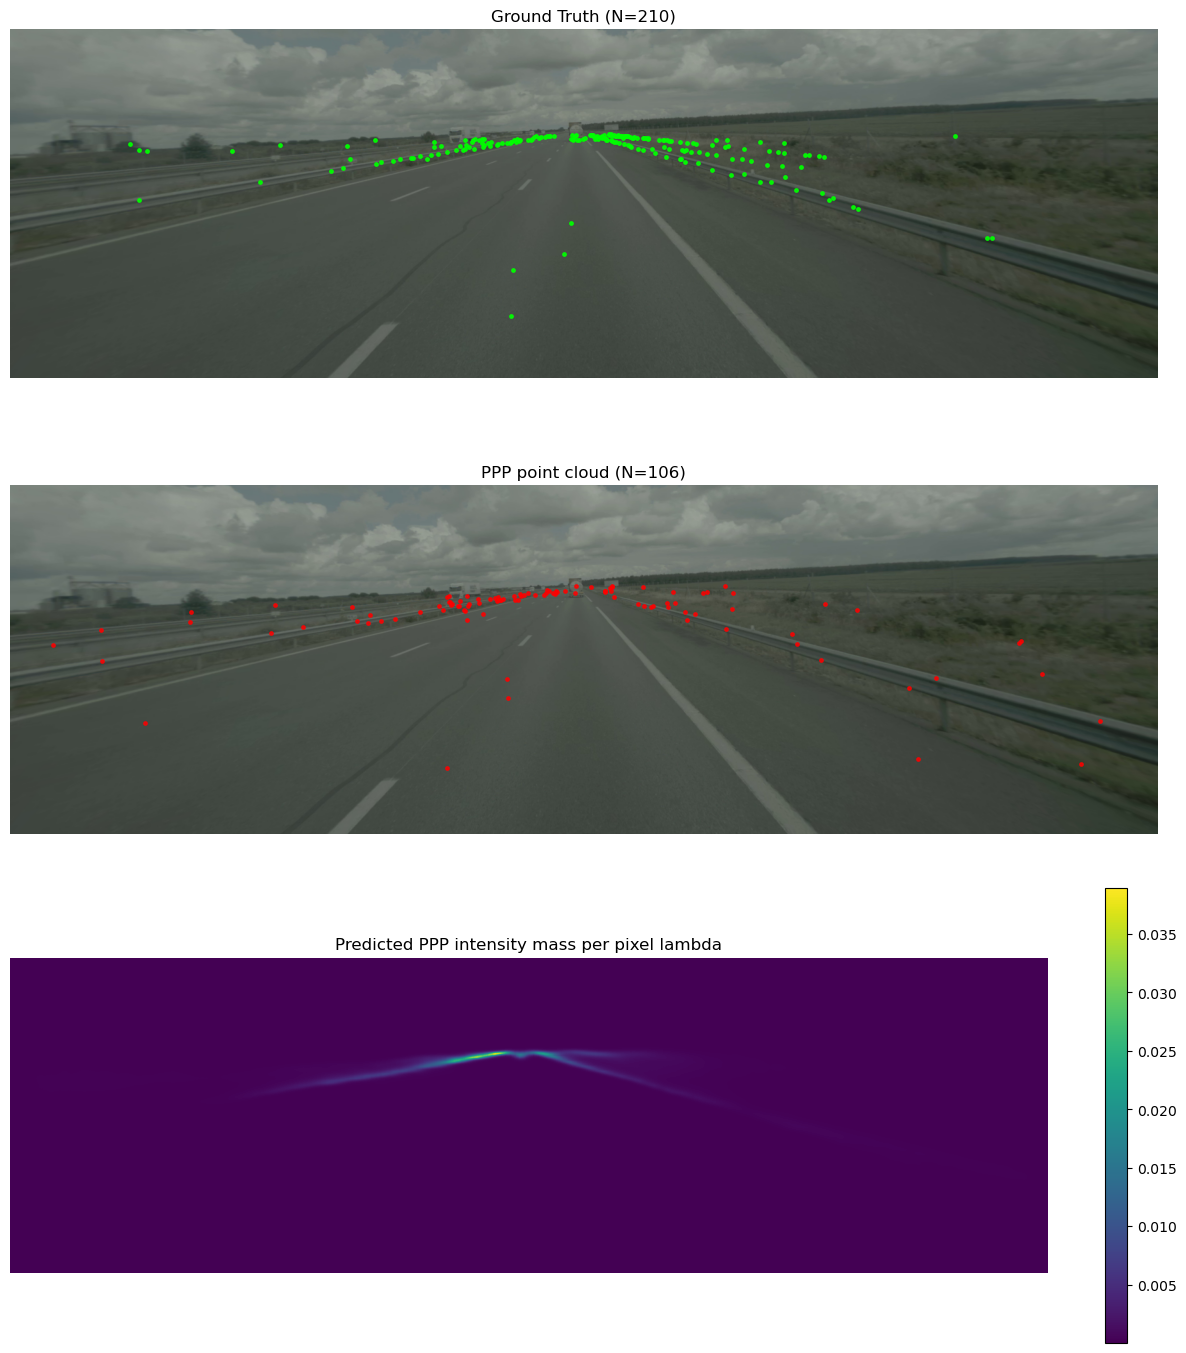

In [29]:
s = load_sample(prefix)

# PPP thinning
H, W = s["pred_lambda_mass"].shape
pixel_area = 1.0  # kept for API compatibility, not used

ppp_points, N, lam_max, N_prop = sample_ppp_by_thinning(
    s["pred_lambda_mass"],
    pixel_area=pixel_area,
)

print("Lambda max:", lam_max)
print("Accepted points:", N)
print("Expected count:", s["ppp"]["expected_count"])
print("GT count:", s["ppp"]["gt_count"])
print("Acceptance rate:", N / max(N_prop, 1))

# GT points (from GT mask / count map)
gt_points = extract_gt_points_from_mask(s["gt_point_support"])

visualize_gt_ppp_heatmap(
    img=s["img"],
    gt_points_xy=gt_points,
    ppp_points_xy=ppp_points,
    lambda_grid=s["pred_lambda_mass"],
)

### Blockwise Bernoulli Point Placement via Empty Space Probabilities

In [30]:
def sample_points_block_bernoulli(
    lambda_grid: np.ndarray,
    *,
    block_size: int = 8,
    pixel_area: float = 1.0,
    placement: str = "weighted",   # "weighted" or "uniform"
    # Controls where inside an active block the point is placed:
    # "uniform" → uniform in block area, "weighted" → proportional to λ inside the block
    rng: np.random.Generator | None = None,
    # Optional random number generator for reproducibility.
):
    """
    Block/Bernoulli approximation of a PPP:
      For each block A:
        Λ_A = sum_{A} λ
        Activate block with p_A = 1 - exp(-Λ_A)
      If active, place exactly one point in A.

    Returns
    -------
    points_xy : (N,2) array in image coords
    stats : dict with diagnostics
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    assert np.all(np.isfinite(lam)), "lambda_grid contains NaN/Inf."
    assert np.all(lam >= 0), "lambda_grid contains negative values."

    H, W = lam.shape
    bs = int(block_size)
    assert bs > 0

    points = []
    num_blocks = 0
    num_active = 0
    expected_blocks_active = 0.0  # sum p_A

    # Iterate over the image in non-overlapping block_size × block_size blocks.
    for y0 in range(0, H, bs):
        for x0 in range(0, W, bs):
            # Handle boundary blocks at the image edges.
            y1 = min(y0 + bs, H)
            x1 = min(x0 + bs, W)
            num_blocks += 1

            # Expected count in block
            block = lam[y0:y1, x0:x1]
            Lambda_A = block.sum()

            if Lambda_A <= 0:
                continue
            
            # probability that there is at least one dot in the square (Bernoulli experiment)
            pA = 1.0 - np.exp(-Lambda_A)
            # we track the expected number of blocks that should become active (sanity check)
            expected_blocks_active += pA

            # Perform Bernoulli experiment
            if rng.random() >= pA:
                # block inactive
                continue
            
            # block active
            num_active += 1
            
            # Placement of the point in the block
            hB, wB = block.shape

            if placement == "uniform" or block.sum() == 0:
                # uniform point inside the block
                x = x0 + rng.random() * wB
                y = y0 + rng.random() * hB

            elif placement == "weighted":
                # choose a pixel proportional to λ inside the block, then jitter within pixel
                probs = (block / block.sum()).ravel()
                idx = rng.choice(probs.size, p=probs)
                by, bx = divmod(idx, wB)
                x = x0 + bx + rng.random()
                y = y0 + by + rng.random()

            else:
                raise ValueError("placement must be 'weighted' or 'uniform'")

            points.append([x, y])

    points_xy = np.asarray(points, dtype=np.float64) if points else np.zeros((0, 2), dtype=np.float64)

    stats = dict(
        block_size=bs,
        placement=placement,
        num_blocks=num_blocks,
        num_active_blocks=num_active,
        expected_active_blocks=float(expected_blocks_active),
        num_points=int(points_xy.shape[0]),
    )
    return points_xy, stats


In [31]:
H, W = s["pred_lambda_mass"].shape
pixel_area = 1.0  # kept for API compatibility, not used

block_points, stats = sample_points_block_bernoulli(
    s["pred_lambda_mass"],
    block_size=8,
    pixel_area=pixel_area,
    placement="weighted",
)

print(stats)

{'block_size': 8, 'placement': 'weighted', 'num_blocks': 15232, 'num_active_blocks': 103, 'expected_active_blocks': 92.79076536787548, 'num_points': 103}


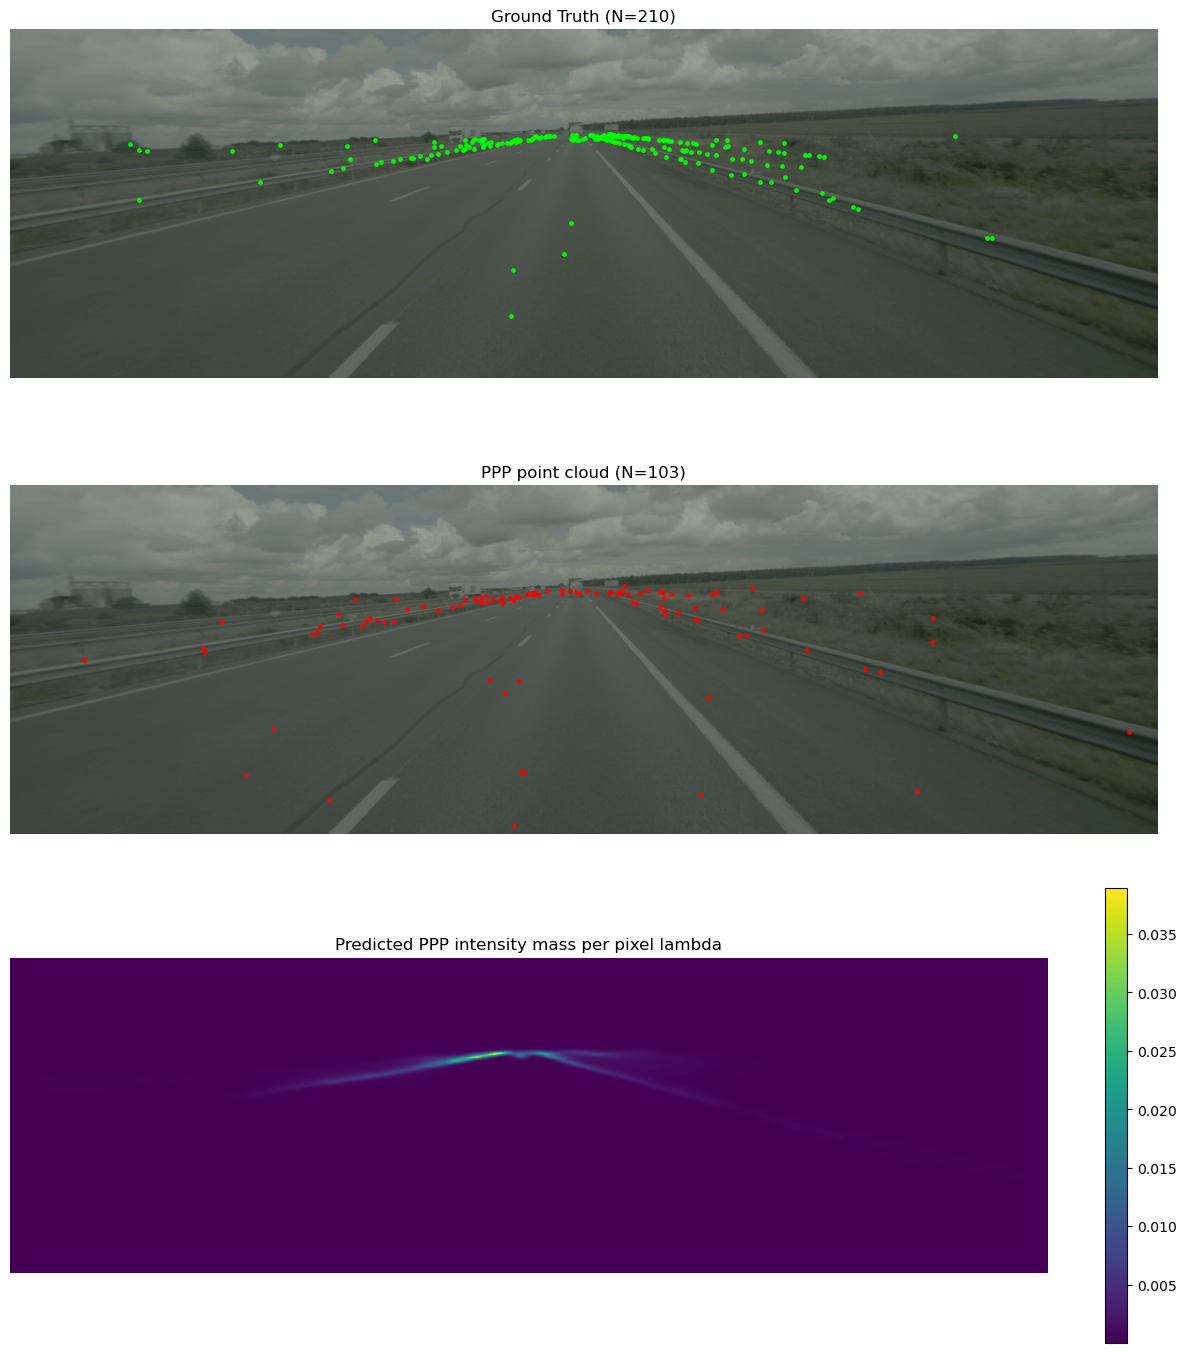

In [32]:
gt_points = extract_gt_points_from_mask(s["gt_point_support"])

visualize_gt_ppp_heatmap(
    img=s["img"],
    gt_points_xy=gt_points,
    ppp_points_xy=block_points,
    lambda_grid=s["pred_lambda_mass"],
)